# Fase 2 — Recorte temporal e vocabulário discriminante

### O que este notebook faz

Extrai a data de publicação de cada registro, descreve a janela temporal coberta pelo corpus e identifica o vocabulário que mais separa as duas classes. O recorte temporal delimita a validade do estudo; o vocabulário discriminante antecipa, já na análise exploratória, o viés institucional que a Fase 7 confirma por LIME.

### Entradas

- `dados/corpus_base.csv`
- `fakerecogna_bruto.csv`

### Saídas de dados

- `dados/corpus_preparado.csv`
- `dados/termos_discriminantes.csv`

### Figuras geradas para o artigo

- `figuras/fig_corpus_temporal.png` — notícias por ano e por classe, com a janela coberta
- `figuras/fig_corpus_termos.png` — termos de maior razão de chances entre as classes

## 1. Ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

A célula abaixo grava o módulo `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC — largura útil, corpo tipográfico, resolução e separação de luminância para impressão em preto e branco. Por ser o mesmo módulo nas oito fases, nenhuma figura do artigo sai fora do padrão.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-

import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image


AZUL    = '#1B4F72'
LARANJA = '#D55E00'
AMBAR   = '#E8B04B'
VERDE   = '#117733'
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

AZUL_TEXTO    = AZUL
LARANJA_TEXTO = '#A64A00'
AMBAR_TEXTO   = '#8A6410'
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

T_PEQUENO  = 8.0
T_CORPO    = 9.0
T_ROTULO   = 9.5
T_TITULO   = 10.5
T_DESTAQUE = 13.0


def legivel(cor):
    """Variante da cor com contraste suficiente para texto sobre branco."""
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}


MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])


CM = 1 / 2.54
LARGURA = 15 * CM
LARGURA_MEIA = 7.2 * CM


_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')


mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})


_destino = Path('.')


def destino(pasta):
    """Define a pasta onde salvar() grava as figuras."""
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):

    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho



def br(texto):
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    """Eixo numerico comum, tambem com virgula decimal."""
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):

    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
def arquivo(*nomes):
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Carga e extração de datas

A data não vem em um campo normalizado: aparece dentro do texto e do endereço de origem, em formatos diferentes. A função abaixo tenta dois padrões e descarta combinações impossíveis — sem o `try`, uma data como 32/13/2020 interromperia a execução.

In [5]:
import re

df = pd.read_csv(arquivo('corpus_base.csv'))
bruto = pd.read_csv(arquivo('fakerecogna_bruto.csv', 'FakeRecogna.csv'))
if 'indice_origem' in df.columns:
    chaves = df['indice_origem'].to_numpy()
    if chaves.max() >= len(bruto) or chaves.min() < 0:
        raise ValueError(
            'indice_origem aponta para linhas que não existem no arquivo '
            'bruto ({} linhas). Os dois arquivos vieram de execuções '
            'diferentes: rode a Fase 1 novamente.'.format(len(bruto)))
    bruto = bruto.loc[chaves].reset_index(drop=True)
elif len(bruto) != len(df):
    raise ValueError(
        'corpus_base.csv tem {} linhas e o arquivo bruto {}, e não há coluna '
        'indice_origem para alinhar. Rode a Fase 1 novamente.'
        .format(len(df), len(bruto)))
campo_noticia = coluna(bruto, 'noticia', 'notícia', 'news', 'texto')
amostra = df.sample(min(200, len(df)), random_state=0).index
casam = 0
for i in amostra:
    inicio = ' '.join(str(bruto.loc[i, campo_noticia]).split())[:30]
    if inicio and inicio in ' '.join(str(df.loc[i, 'texto']).split()):
        casam += 1
print('alinhamento conferido: {} de {} amostras casam'
      .format(casam, len(amostra)))
if casam < 0.9 * len(amostra):
    raise ValueError('corpus_base.csv e o arquivo bruto estão desalinhados. '
                     'Rode a Fase 1 novamente.')

campo_data = coluna(bruto, 'data', 'date', obrigatoria=False)
campo_url  = coluna(bruto, 'url', 'link', obrigatoria=False)

def extrair_data(texto):
    if pd.isna(texto):
        return pd.NaT
    texto = str(texto)
    for padrao in [r'(\d{1,2})[/-](\d{1,2})[/-](\d{4})',
                   r'(\d{4})[/-](\d{1,2})[/-](\d{1,2})']:
        m = re.search(padrao, texto)
        if m:
            g = m.groups()
            ano, mes, dia = (g[2], g[1], g[0]) if len(g[0]) <= 2 else (g[0], g[1], g[2])
            try:
                return pd.Timestamp(year=int(ano), month=int(mes), day=int(dia))
            except (ValueError, pd.errors.OutOfBoundsDatetime):
                return pd.NaT
    return pd.NaT

fontes = []
if campo_data:
    fontes.append(bruto[campo_data].astype(str))
if campo_url:
    fontes.append(bruto[campo_url].astype(str))
if not fontes:
    raise ValueError('O arquivo bruto não tem coluna de data nem de endereço: '
                     'não há de onde extrair a data de publicação.')
tentativas = pd.DataFrame({
    'fonte_{}'.format(i): pd.to_datetime(serie.map(extrair_data), errors='coerce')
    for i, serie in enumerate(fontes)})
datas = tentativas.bfill(axis=1).iloc[:, 0]

df['data'] = pd.to_datetime(datas.to_numpy(), errors='coerce')
df['ano']  = df['data'].dt.year

recuperadas = int(df['data'].notna().sum())
print('datas recuperadas: {} de {} ({})'
      .format(mil(recuperadas), mil(len(df)), pct(df['data'].notna().mean())))
if recuperadas:
    print('janela:', df['data'].min().date(), 'a', df['data'].max().date())
else:
    print('ATENÇÃO: nenhuma data reconhecida. Confira o formato das colunas '
          'de data e de endereço no arquivo bruto — a figura temporal será '
          'pulada.')
df.to_csv(DADOS / 'corpus_preparado.csv', index=False)


alinhamento conferido: 200 de 200 amostras casam
datas recuperadas: 11.327 de 11.902 (95,2%)
janela: 2012-02-09 a 2021-09-07


## 5. Figura — distribuição temporal

Barras empilhadas, uma por ano. A primeira versão desta figura usava área empilhada e estava errada: o corpus quase não tem registros entre 2013 e 2017, e a área ligava 2014 a 2018 com uma rampa reta, desenhando um crescimento que não existe nos dados. Barra não interpola — ano sem registro aparece como espaço vazio, que é o que ele é.

classe  Falsa  Verdadeira
ano                      
2012        1           0
2013        0           0
2014        1           0
2015        0           0
2016        0           0
2017        0           0
2018       94           0
2019     1494           8
2020     2701        3980
2021     1308        1740
[figura] fig_corpus_temporal.png        15.0 x 9.5 cm  (margem branca completada)


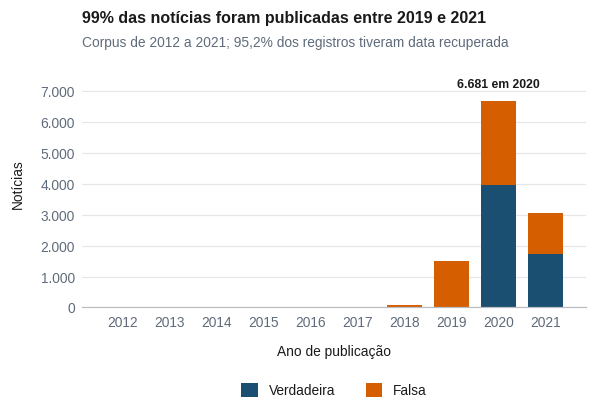

In [6]:
por_ano = (df.dropna(subset=['ano'])
             .pivot_table(index='ano', columns='classe', values='texto',
                          aggfunc='size')
             .fillna(0).sort_index())
if por_ano.empty:
    raise ValueError('Nenhuma data foi reconhecida na célula anterior, então '
                     'não há série temporal para desenhar. Confira o formato '
                     'das colunas de data e de endereço no arquivo bruto.')
por_ano.index = por_ano.index.astype(int)

anos = list(range(int(por_ano.index.min()), int(por_ano.index.max()) + 1))
por_ano = por_ano.reindex(anos, fill_value=0)
print(por_ano.astype(int).to_string())

serie_v = por_ano.get('Verdadeira', pd.Series(0, index=por_ano.index))
serie_f = por_ano.get('Falsa', pd.Series(0, index=por_ano.index))
total = por_ano.sum(axis=1)

acumulado = total.cumsum() / total.sum()
inicio = int(total.index[int((acumulado >= 0.05).argmax())])
fim    = int(total.index[int((acumulado >= 0.95).argmax())])
concentracao = total.loc[inicio:fim].sum() / total.sum()

fig, ax = plt.subplots(figsize=(LARGURA, 7.4 * CM))
ax.bar(por_ano.index, serie_v, width=0.74, color=AZUL, label='Verdadeira')
ax.bar(por_ano.index, serie_f, width=0.74, bottom=serie_v, color=LARANJA,
       label='Falsa')

pico = int(total.idxmax())
ax.annotate(mil(total.max()) + ' em ' + str(pico), xy=(pico, total.max()),
            xytext=(0, 7), textcoords='offset points', ha='center',
            va='bottom', fontsize=T_PEQUENO, fontweight='bold', color=TEXTO)

grade_y(ax)
eixo_milhar(ax, 'y')
ax.set_xticks(anos)
ax.tick_params(axis='x', labelrotation=0 if len(anos) <= 12 else 45)
ax.set_xlabel('Ano de publicação')
ax.set_ylabel('Notícias')
folga(ax, 'y', 0.14)
legenda_abaixo(ax)
titulo(ax, '{} das notícias foram publicadas entre {} e {}'
       .format(pct(concentracao, 0), inicio, fim),
       'Corpus de {} a {}; {} dos registros tiveram data recuperada'
       .format(anos[0], anos[-1], pct(df['data'].notna().mean())))
salvar(fig, 'fig_corpus_temporal')
plt.show()


## 6. Figura — vocabulário discriminante

A medida é a razão de chances logarítmica suavizada: para cada termo, o quanto sua frequência relativa em uma classe excede a da outra. Barras divergentes a partir de um eixo central, porque o sinal da medida é a informação principal — de que lado o termo empurra a classificação.

[figura] fig_corpus_termos.png          15.0 x 12.3 cm  (margem branca completada)


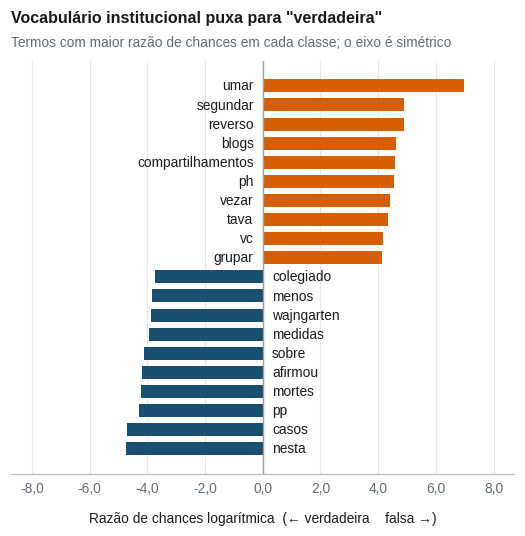

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
PARADAS = stopwords.words('portuguese')

vec = CountVectorizer(max_features=4000, min_df=10, stop_words=PARADAS)
X = vec.fit_transform(df['texto'].fillna(''))
termos = np.array(vec.get_feature_names_out())

mascara = (df['classe'] == 'Falsa').values
cont_falsa = np.asarray(X[mascara].sum(axis=0)).ravel() + 1.0
cont_verd  = np.asarray(X[~mascara].sum(axis=0)).ravel() + 1.0
p_falsa = cont_falsa / cont_falsa.sum()
p_verd  = cont_verd / cont_verd.sum()
razao   = np.log(p_falsa / p_verd)

k = 10
ordem = np.argsort(razao)
sel = np.concatenate([ordem[:k], ordem[-k:]])
tab = (pd.DataFrame({'termo': termos[sel], 'log_razao': razao[sel]})
       .sort_values('log_razao'))
tab.to_csv(DADOS / 'termos_discriminantes.csv', index=False)

fig, ax = plt.subplots(figsize=(LARGURA, 0.46 * CM * len(tab) + 3.2 * CM))
cores = [AZUL if v < 0 else LARANJA for v in tab['log_razao']]
barras = ax.barh(tab['termo'], tab['log_razao'], color=cores, height=0.68)

for b, t, v in zip(barras, tab['termo'], tab['log_razao']):
    ax.annotate(t, xy=(0, b.get_y() + b.get_height() / 2),
                xytext=(6 if v < 0 else -6, 0), textcoords='offset points',
                ha='left' if v < 0 else 'right', va='center',
                fontsize=T_CORPO, color=TEXTO)
ax.set_yticks([])
ax.axvline(0, color='#9AA0A6', linewidth=0.9)
grade_x(ax)
eixo_decimal(ax, 'x', 1)
ax.spines['bottom'].set_visible(True)
ax.set_xlabel('Razão de chances logarítmica  (← verdadeira    falsa →)')
lim = np.abs(tab['log_razao']).max() * 1.25
ax.set_xlim(-lim, lim)
titulo(ax, 'Vocabulário institucional puxa para "verdadeira"',
       'Termos com maior razão de chances em cada classe; o eixo é simétrico')
salvar(fig, 'fig_corpus_termos')
plt.show()


> **Leitura.** Os termos do lado "verdadeira" são de registro institucional — órgãos públicos, cargos, cidades. Isso ainda não é prova de atalho preditivo, mas é a primeira evidência do padrão que a Fase 7 confirma por LIME e que explica porquê notícias sintéticas geradas a partir de manchetes reais escapam da detecção.